<a href="https://colab.research.google.com/github/moushi21/microduck_rl/blob/develop/microduck_jump_training_and_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install uv and Clone Repository
- Runtime check: Ensure the Colab runtime is set to NVIDIA L4 GPU (`Runtime` > `Change runtime type` > `L4 GPU`).
- Install `uv` for ultra-fast, reproducible dependency management.
- Clone the `microduck_rl` repository and enter the project directory.

In [ ]:
# Verify GPU environment
!nvidia-smi

!pip install uv
!git clone https://github.com/moushi21/microduck_rl.git
%cd microduck_rl

## 2. Setup Dependencies (PyTorch with CUDA Acceleration)
- Synchronize all project dependencies defined in `pyproject.toml` using `uv sync`.
- Automatically sets up MuJoCo Warp, rsl_rl (PPO), and CUDA-enabled PyTorch.
- Run a quick sanity check to verify that PyTorch detects the NVIDIA L4 GPU.

In [ ]:
!uv pip install --system torch torchvision --index-url https://download.pytorch.org/whl/cu121
!uv pip install --system -e .

## 3. Verify Registered Task: `Mjlab-Jump-Flat-MicroDuck`
- Inspect the live environment registry using `uv run list-envs`.
- Confirm that the newly implemented `Mjlab-Jump-Flat-MicroDuck` task is successfully registered and available for training.

In [ ]:
!uv sync
!uv run list-envs

## 4. Configure WandB via Colab Secrets (Bypassing `wandb-core` Hang)
- Securely fetch the Weights & Biases API key from Colab Secrets (`userdata.get`) to avoid exposing credentials in code.
- Automatically sanitize inputs with `.strip()` to prevent authentication failures caused by invisible trailing spaces.
- **Robust workaround for the `wandb-core` (Go daemon) deadlock**: Bypasses `wandb.login()` entirely by injecting `WANDB_API_KEY` and `WANDB_SILENT` directly into `os.environ`, allowing `rsl_rl` to authenticate seamlessly without freezing.

In [ ]:
from google.colab import userdata
import os
try:
    # 1. Retrieve and sanitize API key
    api_key = userdata.get("WANDB_API_KEY").strip()

    # 2. Inject into environment (bypassing interactive login hang)
    os.environ["WANDB_API_KEY"] = api_key
    os.environ["WANDB_SILENT"] = "true"
    print("✓ Successfully configured WANDB_API_KEY in environment.")

except userdata.SecretNotFoundError:
    print("✗ Error: 'WANDB_API_KEY' is not registered in Colab Secrets (left sidebar 🔑 icon).")

## 5. Smoke Test (5-Iteration Rapid Verification)
- Run a minimal 5-iteration smoke test with 64 parallel environments (`--env.scene.num-envs 64 --agent.max_iterations 5`).
- Catches ~95% of configuration errors, NaN crashes, and tensor mismatches in seconds before launching full-scale training.
- Log in to your Weights & Biases web dashboard and verify that the run is created and streaming metrics (e.g., `Episode_Reward`, loss curves) successfully.

In [ ]:
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Jump-Flat-MicroDuck \
  --env.scene.num-envs 64 \
  --agent.resume False \
  --agent.max_iterations 5

## 6. Full-Scale Jump Policy Training (8,000 Iterations)
- **Training Parameters**: Configured for 8,000 iterations (`--agent.max_iterations 8000`) with 4,096 parallel environments (`--env.scene.num-envs 4096`). Default budget is 50,000 iterations.
- **Estimated Runtime**: Takes approximately 50 minutes per 1,000 iterations, requiring ~6.5 to 7 hours in total on an NVIDIA L4 GPU.
- **Colab Anti-Freeze Optimization**: Console stdout is redirected to `/dev/null` (`> /dev/null 2>&1`) to prevent browser tab crashes caused by massive log buffer overflow. Real-time training metrics, reward curves, and loss values are monitored live on the Weights & Biases dashboard.
- **Curriculum Completion Requirement**: The task executes a 4-stage dual curriculum (air-time threshold & action rate penalty). A minimum of 5,000 iterations is strictly required to progress through all stages and master the final Stage 4 full jump.
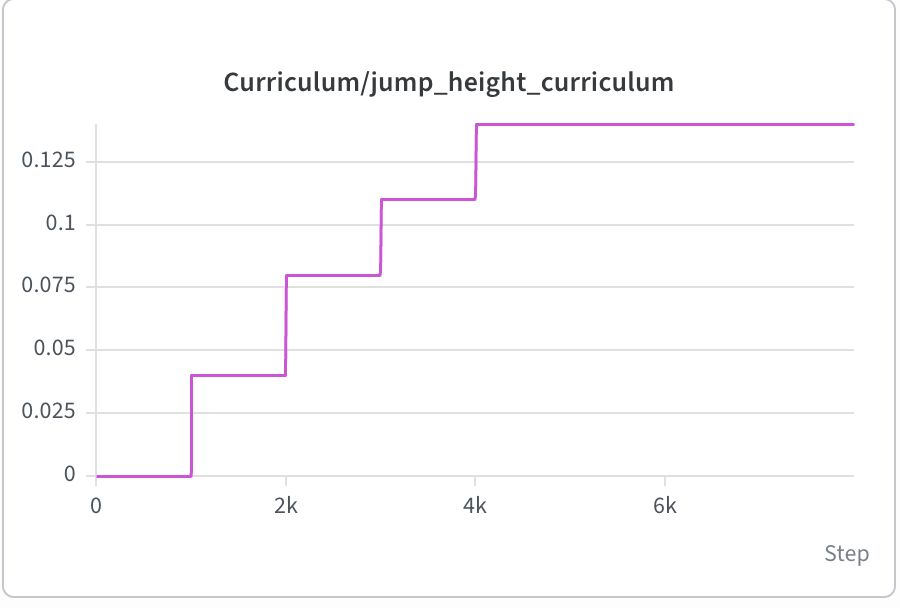

In [ ]:
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Jump-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume False \
  --agent.max_iterations 8000 > /dev/null 2>&1

## 7. Policy Rollout & Video Rendering (WandB Checkpoint Evaluation)

### Command & Parameter Breakdown
- `xvfb-run -s "-screen 0 1280x720x24"`: Creates a virtual X11 framebuffer since Google Colab lacks a physical display, enabling headless offscreen GPU rendering.
- `uv run play Mjlab-Jump-Flat-MicroDuck`: Specifies the trained Jump task environment to evaluate.
- `--wandb-run-path <entity/project/run_id>`: Specifies the target WandB run path (e.g., `.../qz2adxse`).
- `--num-envs 1`: Spawns a single robot instance to ensure smooth, centered camera tracking during recording.
- `--video True --video-width 1280 --video-height 720`: Enables MP4 video recording (1920x1080 recommended for high-fidelity presentation).
- `--video-length 3500`: Total recorded rollout steps. At a 50 Hz control frequency, **3,500 steps yields exactly 70 seconds** of footage ($70\text{ s} = 3500 / 50\text{ Hz}$).
- `--no-terminations True`: **[CRITICAL] Disables standard 8-second episode timeout resets.** This is essential to rigorously demonstrate that the policy has acquired a stable, continuous limit-cycle jump without falling over 70 seconds.
- `--viewer native`: Leverages the native MuJoCo offscreen renderer.

### Technical Notes on Inference & Rendering
- **61D Shared Observation Space**: Executes closed-loop policy inference feeding the exact 61-dimensional observation vector (48D proprioception + 13D command block) required for physical hardware deployment.
- **Rendering Duration**: High-quality offscreen rendering for 3,500 frames takes approximately **45 to 60 minutes**. Please wait for the process to complete or stop after ~1 hour.
- **Output Video Location**: The rendered `.mp4` video will be saved under the `logs/rsl_rl/.../videos/` directory. You can download and preview it directly from Colab's left sidebar file explorer (📁 icon).

In [ ]:
import os

# Configure GPU offscreen rendering backends (EGL)
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# Execute headless rollout and video rendering using xvfb-run and native viewer
!xvfb-run --auto-servernum --server-args="-screen 0 1920x1080x24" \
    uv run play Mjlab-Jump-Flat-MicroDuck \
    --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/qz2adxse \
    --num-envs 1 \
    --video True \
    --video-width 1920 \
    --video-height 1080 \
    --video-length 3500 \
    --no-terminations True \
    --viewer native

## 8. Playback the Rendered Video
- Play the generated rollout video directly inside the notebook.
- **Notice**: The output destination of the `.mp4` file may vary depending on the task configuration. Please search within the `logs/rsl_rl/` directory, set the appropriate `video_path`, and then play the video.

In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

# Exact file path to the rendered rollout video
video_path = "logs/rsl_rl/jump/wandb_checkpoints/qz2adxse/videos/play/rl-video-step-0.mp4"

if os.path.exists(video_path):
    print(f"Loding Video: {video_path}")
    mp4_data = b64encode(open(video_path, 'rb').read()).decode()
    display(HTML(f'<video width="640" height="480" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
else:
    print(f"Video file not found. Please verify that the rendering cell completed successfully. Path: {video_path}")